In [10]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [2]:
# Load and inspect the training dataset

train_df = pd.read_csv("data/train.csv")

print("Dataset shape:", train_df.shape)
print("\nColumn names:")
print(train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isna().sum())

print("\nTarget distribution:")
print(train_df["poisonous"].value_counts(dropna=False))

display(train_df.head())

Dataset shape: (6499, 8)

Column names:
['cap.shape', 'cap.color', 'bruises', 'stalk.color.above.ring', 'stalk.color.below.ring', 'population', 'Id', 'poisonous']

Missing values:
cap.shape                 0
cap.color                 0
bruises                   0
stalk.color.above.ring    0
stalk.color.below.ring    0
population                0
Id                        0
poisonous                 0
dtype: int64

Target distribution:
poisonous
0    3342
1    3157
Name: count, dtype: int64


,cap.shape,cap.color,bruises,stalk.color.above.ring,stalk.color.below.ring,population,Id,poisonous
0,k,e,False,w,w,v,6573,1
1,f,e,True,p,w,y,4426,0
2,b,w,False,w,w,s,7018,0
3,k,g,False,w,w,n,5789,0
4,f,n,True,p,g,v,6187,0


In [3]:
# Prepare features, target, and stratified train-validation split

X = train_df.drop(columns=["Id", "poisonous"])
y = train_df["poisonous"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12345,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))
print("\nValidation target distribution:")
print(y_valid.value_counts(normalize=True))

Training shape: (5199, 6)
Validation shape: (1300, 6)

Training target distribution:
poisonous
0    0.514137
1    0.485863
Name: proportion, dtype: float64

Validation target distribution:
poisonous
0    0.514615
1    0.485385
Name: proportion, dtype: float64


In [4]:
# Train and evaluate the baseline classifier

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_valid)

print("Baseline recall:", recall_score(y_valid, baseline_predictions, pos_label=1))
print("Baseline precision:", precision_score(
    y_valid,
    baseline_predictions,
    pos_label=1,
    zero_division=0
))
print("\nConfusion matrix:")
print(confusion_matrix(y_valid, baseline_predictions))

Baseline recall: 0.0
Baseline precision: 0.0

Confusion matrix:
[[669   0]
 [631   0]]


In [5]:
# Train and evaluate the Logistic Regression classifier

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", OneHotEncoder(handle_unknown="ignore")),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=12345
    ))
])

logistic_pipeline.fit(X_train, y_train)

logistic_predictions = logistic_pipeline.predict(X_valid)

print("Logistic Regression recall:", recall_score(
    y_valid, logistic_predictions, pos_label=1
))

print("Logistic Regression precision:", precision_score(
    y_valid, logistic_predictions, pos_label=1
))

print("\nConfusion matrix:")
print(confusion_matrix(y_valid, logistic_predictions))

print("\nClassification report:")
print(classification_report(y_valid, logistic_predictions))

Logistic Regression recall: 0.9080824088748018
Logistic Regression precision: 0.8761467889908257

Confusion matrix:
[[588  81]
 [ 58 573]]

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.89       669
           1       0.88      0.91      0.89       631

    accuracy                           0.89      1300
   macro avg       0.89      0.89      0.89      1300
weighted avg       0.89      0.89      0.89      1300



In [6]:
# Train and evaluate the Random Forest classifier

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", OneHotEncoder(handle_unknown="ignore")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=12345,
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train)

rf_predictions = random_forest_pipeline.predict(X_valid)

print("Random Forest recall:", recall_score(
    y_valid, rf_predictions, pos_label=1
))

print("Random Forest precision:", precision_score(
    y_valid, rf_predictions, pos_label=1
))

print("\nConfusion matrix:")
print(confusion_matrix(y_valid, rf_predictions))

print("\nClassification report:")
print(classification_report(y_valid, rf_predictions))

Random Forest recall: 0.9809825673534073
Random Forest precision: 0.9322289156626506

Confusion matrix:
[[624  45]
 [ 12 619]]

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.96       669
           1       0.93      0.98      0.96       631

    accuracy                           0.96      1300
   macro avg       0.96      0.96      0.96      1300
weighted avg       0.96      0.96      0.96      1300



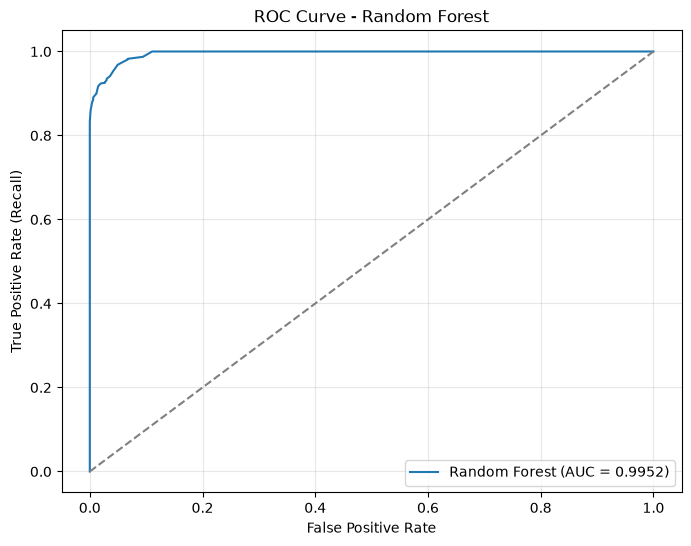

ROC AUC: 0.9952


In [7]:
# Plot the ROC curve for the Random Forest classifier

rf_probabilities = random_forest_pipeline.predict_proba(X_valid)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_valid,
    rf_probabilities,
    pos_label=1
)

rf_auc = roc_auc_score(y_valid, rf_probabilities)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {rf_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"ROC AUC: {rf_auc:.4f}")

In [8]:
# Evaluate recall and precision at different decision thresholds

threshold_results = []

for threshold in np.arange(0.05, 0.55, 0.05):
    predictions = (rf_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Recall": recall_score(y_valid, predictions, pos_label=1),
        "Precision": precision_score(
            y_valid, predictions, pos_label=1, zero_division=0
        ),
        "False Negatives": int(((y_valid == 1) & (predictions == 0)).sum()),
        "False Positives": int(((y_valid == 0) & (predictions == 1)).sum())
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Recall,Precision,False Negatives,False Positives
0,0.05,1.000000,0.888732,0,79
1,0.10,1.000000,0.892504,0,76
2,0.15,1.000000,0.892504,0,76
3,0.20,1.000000,0.895035,0,74
4,0.25,0.987322,0.908163,8,63
5,0.30,0.982567,0.932331,11,45
6,0.35,0.982567,0.932331,11,45
7,0.40,0.982567,0.932331,11,45
8,0.45,0.982567,0.932331,11,45
9,0.50,0.980983,0.932229,12,45


In [9]:
# Evaluate Random Forest at the selected candidate threshold

candidate_threshold = 0.20

candidate_predictions = (
    rf_probabilities >= candidate_threshold
).astype(int)

print("Candidate threshold:", candidate_threshold)

print("Recall:", recall_score(
    y_valid, candidate_predictions, pos_label=1
))

print("Precision:", precision_score(
    y_valid, candidate_predictions, pos_label=1
))

print("\nConfusion matrix:")
print(confusion_matrix(y_valid, candidate_predictions))

print("\nClassification report:")
print(classification_report(y_valid, candidate_predictions))

Candidate threshold: 0.2
Recall: 1.0
Precision: 0.8950354609929078

Confusion matrix:
[[595  74]
 [  0 631]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94       669
           1       0.90      1.00      0.94       631

    accuracy                           0.94      1300
   macro avg       0.95      0.94      0.94      1300
weighted avg       0.95      0.94      0.94      1300



In [11]:
# Evaluate the candidate threshold using stratified cross-validation

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=12345
)

cv_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv_strategy.split(X_train, y_train), start=1
):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_valid = X_train.iloc[valid_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    fold_model = clone(random_forest_pipeline)
    fold_model.fit(X_fold_train, y_fold_train)

    fold_probabilities = fold_model.predict_proba(X_fold_valid)[:, 1]
    fold_predictions = (
        fold_probabilities >= candidate_threshold
    ).astype(int)

    cv_results.append({
        "Fold": fold,
        "Recall": recall_score(y_fold_valid, fold_predictions),
        "Precision": precision_score(
            y_fold_valid, fold_predictions, zero_division=0
        ),
        "False Negatives": int(
            ((y_fold_valid == 1) & (fold_predictions == 0)).sum()
        ),
        "False Positives": int(
            ((y_fold_valid == 0) & (fold_predictions == 1)).sum()
        )
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

print("Mean CV Recall:", cv_results_df["Recall"].mean())
print("Mean CV Precision:", cv_results_df["Precision"].mean())
print("Total False Negatives:", cv_results_df["False Negatives"].sum())

,Fold,Recall,Precision,False Negatives,False Positives
0,1,1.00000,0.881533,0,68
1,2,1.00000,0.903399,0,54
2,3,0.99802,0.916364,1,46
3,4,0.99802,0.887324,1,64
4,5,1.00000,0.881326,0,68


Mean CV Recall: 0.9992079207920792
Mean CV Precision: 0.8939891920512373
Total False Negatives: 2


In [12]:
# Compare decision thresholds using out-of-fold predictions

from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    estimator=random_forest_pipeline,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_comparison = []

for threshold in np.arange(0.05, 0.55, 0.05):
    predictions = (oof_probabilities >= threshold).astype(int)

    threshold_comparison.append({
        "Threshold": round(threshold, 2),
        "Recall": recall_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "False Negatives": int(
            ((y_train == 1) & (predictions == 0)).sum()
        ),
        "False Positives": int(
            ((y_train == 0) & (predictions == 1)).sum()
        )
    })

oof_threshold_df = pd.DataFrame(threshold_comparison)

display(oof_threshold_df)

,Threshold,Recall,Precision,False Negatives,False Positives
0,0.05,0.999604,0.888772,1,316
1,0.10,0.999604,0.891596,1,307
2,0.15,0.999208,0.893451,2,301
3,0.20,0.999208,0.893768,2,300
4,0.25,0.986936,0.924360,33,204
5,0.30,0.984956,0.930093,38,187
6,0.35,0.984561,0.935666,39,171
7,0.40,0.984561,0.935666,39,171
8,0.45,0.984561,0.935666,39,171
9,0.50,0.961203,0.949550,98,129


In [13]:
# Evaluate the selected threshold on the validation dataset

selected_threshold = 0.10

final_validation_predictions = (
    rf_probabilities >= selected_threshold
).astype(int)

print("Selected threshold:", selected_threshold)

print("Validation recall:", recall_score(
    y_valid, final_validation_predictions, pos_label=1
))

print("Validation precision:", precision_score(
    y_valid, final_validation_predictions, pos_label=1
))

print("\nConfusion matrix:")
print(confusion_matrix(y_valid, final_validation_predictions))

print("\nClassification report:")
print(classification_report(y_valid, final_validation_predictions))

Selected threshold: 0.1
Validation recall: 1.0
Validation precision: 0.8925035360678925

Confusion matrix:
[[593  76]
 [  0 631]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94       669
           1       0.89      1.00      0.94       631

    accuracy                           0.94      1300
   macro avg       0.95      0.94      0.94      1300
weighted avg       0.95      0.94      0.94      1300



In [14]:
# Train the final model and generate the competition submission

from pathlib import Path

# Train on the full labeled dataset
final_model = clone(random_forest_pipeline)
final_model.fit(X, y)

# Load competition test data
competition_test = pd.read_csv("data/test.csv")

# Prepare test features in the same order as training
X_competition = competition_test[X.columns]

# Predict poisonous probabilities and apply the selected threshold
competition_probabilities = final_model.predict_proba(
    X_competition
)[:, 1]

competition_predictions = (
    competition_probabilities >= selected_threshold
).astype(int)

# Create submission file
submission = pd.DataFrame({
    "Id": competition_test["Id"],
    "poisonous": competition_predictions
})

# Validate submission format
example_submission = pd.read_csv(
    "data/output/example_submission.csv"
)

assert submission.columns.tolist() == example_submission.columns.tolist()
assert len(submission) == len(example_submission)
assert submission["Id"].is_unique
assert submission["poisonous"].isin([0, 1]).all()

# Save submission
output_path = Path("data/output/mushroom_submission.csv")
submission.to_csv(output_path, index=False)

print("Selected model: Random Forest")
print("Decision threshold:", selected_threshold)
print("Submission shape:", submission.shape)
print("Submission saved to:", output_path)
print("\nPredicted class distribution:")
print(submission["poisonous"].value_counts())

Selected model: Random Forest
Decision threshold: 0.1
Submission shape: (1625, 2)
Submission saved to: data\output\mushroom_submission.csv

Predicted class distribution:
poisonous
1    849
0    776
Name: count, dtype: int64
